# MCDI505 · Sumativa 4 — Informe ejecutivo del proyecto

| | |
|---|---|
| **Estudiante** | Claudio Rodolfo Alarcón Pradenas |
| **Docente** | Dr. Harvey Jezlid Rosas Quintero |
| **Evaluación** | Sumativa 4 · Semana 4 · Fase 4 — Presentación y comunicación del proyecto |
| **Archivo** | `mcdi505_S4CAlarcon_FINAL.ipynb` |
| **Datos** | `data/raw/consumo_electrico_litoral_depurado.csv` |
| **Repositorio (respaldo y reproducibilidad)** | `https://github.com/claudioalarconP/Analisis_de_serie_de_tiempo` |

**Pregunta de la semana:** ¿Qué consumo espera DEL para los próximos 12 meses, con qué incertidumbre y qué volumen debería contratar?

**Problema y enfoque.** DEL compromete cada diciembre la energía comercial de los 12 meses siguientes: contratar de menos obliga a comprar después a mayor precio y contratar de más paga energía que no se usa (Universidad Andrés Bello [UNAB], s. f.-a). Se evalúa una sola vez en 2024 el modelo seleccionado en la Semana 2 y ratificado en la Semana 3, se compara con el naive estacional y el resultado se traduce en un criterio de contratación, cuyo efecto se cuantifica con los datos reales de 2024.

## Hoja de decisiones

Punto de partida: **M4 = SARIMA(0,1,0)(1,1,0)₁₂** sobre log(consumo), sin variables exógenas, seleccionado en la Sumativa 2 y ratificado en la Sumativa 3. Se reestima con 2015-01 a 2023-12 y se evalúa una sola vez en 2024. Todos los pronósticos puntuales usan la media lognormal exp(μ + σ²/2).

| Criterio | Decisión o conclusión | Evidencia clave (cifra, prueba o figura) | Alternativa descartada | Consecuencia |
|---|---|---|---|---|
| 1. Modelo de partida | Se mantiene M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo), sin exógenas. | S2: menor error de validación 2023 entre M1, M2, M3, M4, M6 y dos naive (M4: RMSE / MAE = 4,12 / 3,71 GWh; Tabla 5b). S3: ARFIMA no mejora (4,19 / 3,75); GARCH sin mejora sustantiva (ancho 45,64 frente a 46,26 GWh). | M1, M2, M3, M6, naive estacional, naive con deriva y extensiones ARFIMA/GARCH | Pasa a la S4 sin cambios (`D_FRACCIONAL = None`, `BANDAS_GARCH = False`). |
| 2. Reestimación 2015–2023 | Mismos órdenes; modelo congelado antes de abrir 2024. | n = 108; Φ1 = −0,36 (ee = 0,094) frente a −0,311 en la S3: 0,5 errores estándar; converge (Tabla 1). | Reespecificar con la información de 2023 | La diferencia no aporta por sí sola evidencia suficiente de cambio estructural ni constituye una prueba formal de estabilidad. |
| 3. Prueba 2024 | 2024 se abre una sola vez, solo para evaluar, con la misma retransformación de 2023. | RMSE = 6,01 y MAE = 5,33 GWh; alterar 2024 no cambia los parámetros (Tabla 3, Fig. 1). | Reestimar con 2024 antes de evaluar | Evaluación fuera de muestra válida. |
| 4. Naive y MASE | M4 supera al naive estacional. | MASE = 0,82 frente a 1,02; RMSE −26,6 % y MAE −20,1 %. El naive con deriva obtiene menor error en 2024 (RMSE 5,80 GWh) (Tabla 3). | Reemplazar M4 por la deriva usando la prueba | Se mantiene M4. |
| 5. Cobertura | Favorable, sin probar calibración. | 12/12 meses dentro; ancho medio 50,7 GWh; un solo año y errores multihorizonte correlacionados. | Afirmar que el IC garantiza la cobertura | El IC dimensiona la incertidumbre. |
| 6. Sesgo 2024 (retroalimentación S3) | La subestimación de 2023 cambia de signo. | 2023: ME = +3,21 GWh, 9/12 subestimados. 2024: ME = −3,66 GWh, 10/12 sobrestimados, +3,0 % anual (Tabla 4). | Corregir el nivel con el error de 2024 | Se declara como limitación; reestimar cada diciembre. |
| 7. Contratación | Contratar mes a mes un cuantil τ* = c_u / (c_u + c_o) > 0,5, por sobre la mediana. | De Q50 a Q75 en 2024: déficit 10,38 → 0,86 GWh (−91,7 %), excedente 45,41 → 143,75 GWh (Tabla 6, Fig. 2). c_u y c_o numéricos no disponibles. | Contratar la mediana o el pronóstico medio | Falta que DEL cuantifique la razón de costos. |
| 8. Limitaciones | Alcance: esta serie y un año de prueba. | 12 meses de prueba; COVID-19 en el ajuste; ρ24 = −0,31; cambio de signo del sesgo; costos no observados (§7). | Generalizar el resultado de 2024 | Afectan la confianza, no la elección de M4. |

### Respuesta al feedback del profesor

| Feedback del profesor | Acción realizada | Evidencia |
|---|---|---|
| Completar alternativas Semana 2 | M1, M2, M3, M4, M6, naive estacional y naive con deriva se recalculan con los datos y criterios de la S2 (estimación 2015–2022, validación 2023) y se contrastan con sus cifras publicadas. M4 se mantiene como modelo seleccionado por su menor RMSE y MAE de validación; 2024 no reabre la selección. | Tabla 5b: M4 4,12 / 3,71 GWh frente a 4,72 / 4,22 del naive con deriva, la mejor alternativa siguiente. |
| Unificar retransformación | Una sola función, `media_lognormal` = exp(μ + σ²/2), para M1–M6 en 2023 y para M4 en 2023, 2024 y 2025; los cuantiles exp(μ + z_τ σ) se reservan para intervalos y contratación. | Tablas 3 y 5b; control final. Prueba 2024: RMSE 6,01, MAE 5,33 GWh, MASE 0,82, ME −3,66 GWh. |
| Cuantificar regla en 2024 | Q50, Q75 y Q80 del pronóstico congelado frente al consumo real 2024: volumen, déficit, excedente y meses con déficit y excedente; el cambio Q50 → Q75 se calcula en código. | Tablas 6–6b y Fig. 2: déficit 10,38 → 0,86 GWh (−91,7 %); excedente +98,34 GWh (+216,6 %); contratado +7,3 %. |

## 0. Reproducibilidad y datos

Serie mensual `consumo_gwh` (2015-01 a 2024-12) del CSV depurado, cargada con rutas relativas, semilla 505 y las funciones de la plantilla oficial (UNAB, s. f.-b); el único cambio es que `ajustar_y_pronosticar` devuelve la media retransformada en lugar de la mediana. La huella SHA-256 del CSV se compara con la informada en la S3. Partición: **2015–2023** para reestimar (108 meses) y **2024** como prueba final (12 meses), que solo se abre en la §3.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
SEMILLA = 505
np.random.seed(SEMILLA)

# Agregados respecto de la plantilla (los mismos de la Sumativa 3, más los de la Semana 4)
import hashlib, platform, json
from pathlib import Path
import scipy, statsmodels, matplotlib
from scipy.stats import norm
from IPython.display import display
from statsmodels.tsa.stattools import acf

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
                     "axes.titlesize": 11, "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False})
ROJO, AZUL, GRIS, VERDE, NARANJA = "#b30338", "#0057b8", "#9e9e9e", "#2e7d32", "#ef6c00"
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__} | "
      f"statsmodels {statsmodels.__version__} | matplotlib {matplotlib.__version__} | semilla = {SEMILLA}")

# ==============================================================================
# Funciones de apoyo (las mismas de la Sesión 3, más tres envoltorios para DEL)
# ==============================================================================

def calcular_exponente_hurst(serie, min_ventana=8, max_ventana=None, n_ventanas=10):
    """Exponente de Hurst por Rango Reescalado (R/S). Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    if max_ventana is None:
        max_ventana = n // 4
    ventanas = np.unique(np.geomspace(min_ventana, max_ventana, num=n_ventanas, dtype=int))
    rs_promedio, ventanas_validas = [], []
    for w in ventanas:
        m = n // w
        if m < 1:
            continue
        rs_bloques = []
        for i in range(m):
            bloque = serie[i * w:(i + 1) * w]
            recorrido = np.cumsum(bloque - np.mean(bloque))
            desviacion = np.std(bloque)
            if desviacion > 0:
                rs_bloques.append((np.max(recorrido) - np.min(recorrido)) / desviacion)
        if rs_bloques:
            rs_promedio.append(np.mean(rs_bloques))
            ventanas_validas.append(w)
    pendiente, _ = np.polyfit(np.log(ventanas_validas), np.log(rs_promedio), 1)
    return pendiente


def aplicar_filtro_fraccional(serie, d):
    """Operador (1-B)^d. d > 0 diferencia fraccionalmente; d < 0 integra. Ver Sesión 3, §2.3."""
    serie = np.asarray(serie, dtype=float)
    n = len(serie)
    pesos = np.zeros(n)
    pesos[0] = 1.0
    for k in range(1, n):
        pesos[k] = pesos[k - 1] * (k - 1 - d) / k
    return np.array([np.sum(pesos[:t + 1] * serie[t::-1]) for t in range(n)])


def garch_log_verosimilitud_negativa(parametros, serie):
    """Log-verosimilitud negativa de un GARCH(1,1) gaussiano. Ver Sesión 3, §3.4."""
    omega, alpha, beta = parametros
    sigma2 = np.zeros(len(serie))
    sigma2[0] = np.var(serie)
    for t in range(1, len(serie)):
        sigma2[t] = omega + alpha * serie[t - 1] ** 2 + beta * sigma2[t - 1]
    if np.any(sigma2 <= 1e-8):
        return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi) + np.log(sigma2) + serie ** 2 / sigma2)


def correccion_arfima(residuos, d, h):
    """Pronóstico h pasos del componente ARFIMA(0,d,0) de los residuos.

    Diferencia fraccionalmente los residuos con d, pronostica cero (ruido blanco)
    y vuelve a integrar con -d. Lo que queda es la persistencia que la memoria
    larga añadiría al pronóstico del SARIMA (en escala logarítmica).
    """
    r = np.asarray(residuos, dtype=float)
    extendida = np.concatenate([aplicar_filtro_fraccional(r, d), np.zeros(h)])
    return aplicar_filtro_fraccional(extendida, -d)[len(r):]


def estimar_garch11(residuos, h):
    """Estima un GARCH(1,1) por MLE sobre los residuos estandarizados.

    Devuelve un diccionario con omega, alpha, beta, persistencia, convergencia,
    residuos estandarizados por sigma_t y el factor de escala de la desviación
    estándar condicional para los h meses siguientes (1 = igual a la varianza
    incondicional).
    """
    r = np.asarray(residuos, dtype=float)
    s = r.std()
    u = r / s
    res = minimize(garch_log_verosimilitud_negativa, x0=[0.05, 0.10, 0.80], args=(u,),
                   bounds=[(1e-6, 5.0), (1e-6, 0.999), (1e-6, 0.999)],
                   constraints=({"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]},),
                   method="SLSQP")
    om, al, be = res.x
    sigma2 = np.zeros(len(u)); sigma2[0] = u.var()
    for t in range(1, len(u)):
        sigma2[t] = om + al * u[t - 1] ** 2 + be * sigma2[t - 1]
    futura = np.zeros(h)
    futura[0] = om + al * u[-1] ** 2 + be * sigma2[-1]
    for i in range(1, h):
        futura[i] = om + (al + be) * futura[i - 1]
    incondicional = om / (1 - al - be)
    return {"omega": om, "alpha": al, "beta": be, "persistencia": al + be,
            "convergencia": bool(res.success),
            "residuos_estandarizados": u / np.sqrt(sigma2),
            "escala_futura": np.sqrt(futura / incondicional)}


def metricas(real, pred):
    """RMSE y MAE en la escala de los datos (GWh)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e)))}


def cobertura_y_ancho(real, inferior, superior):
    """Proporción de meses dentro del intervalo y ancho promedio del intervalo (GWh)."""
    real, inferior, superior = (np.asarray(x, float) for x in (real, inferior, superior))
    return {"Cobertura": float(np.mean((real >= inferior) & (real <= superior))),
            "Ancho medio": float(np.mean(superior - inferior))}

Python 3.12.5 | numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0 | statsmodels 0.14.6 | matplotlib 3.10.9 | semilla = 505


In [2]:
# Celda de carga de la plantilla con rutas relativas (como en las Sumativas 2 y 3)
ARCHIVO = "consumo_electrico_litoral_depurado.csv"
rutas = [Path(*[".."] * n) / sub / ARCHIVO for n in range(5) for sub in (".", "data", "data/raw", "data/processed")]
ruta = next((r for r in rutas if r.exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No se encontró {ARCHIVO}: ubíquelo junto al notebook o en data/, data/raw o data/processed.")
df = pd.read_csv(ruta, parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)

# Validación de la serie (sin inspeccionar los valores de 2024) y partición final
SHA_S3 = "d308b3605bf47ed8"                                     # huella del CSV informada en la Sumativa 3
sha_csv = hashlib.sha256(ruta.read_bytes()).hexdigest()
assert len(y) == 120 and y.index.equals(pd.date_range("2015-01-01", "2024-12-01", freq="MS")) and y.index.freqstr == "MS"
assert y.index.is_monotonic_increasing and not y.index.duplicated().any() and y.notna().all() and (y > 0).all()
assert sha_csv.startswith(SHA_S3), "el CSV no es el mismo de la Sumativa 3"
train_final, test_final = y[:"2023-12"], y["2024-01":"2024-12"]
assert len(train_final) == 108 and train_final.index[-1] == pd.Timestamp("2023-12-01")
assert len(test_final) == 12 and test_final.index[0] == pd.Timestamp("2024-01-01") and train_final.index.intersection(test_final.index).empty

CARPETA_FIG = ruta.parent.parent.parent / "resultados" / "semana_4" / "S4" if ruta.parent.name == "raw" else Path("figuras_s4")
CARPETA_FIG.mkdir(parents=True, exist_ok=True)
CARPETA_TAB = CARPETA_FIG / "tablas"
CARPETA_TAB.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    """Guarda una figura en resultados/semana_4/S4 (ruta relativa al repositorio)."""
    ruta = CARPETA_FIG / nombre
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    return ruta
def guardar_tabla(tabla, nombre):
    """Guarda una tabla en resultados/semana_4/S4/tablas como CSV."""
    ruta = CARPETA_TAB / nombre
    tabla.to_csv(ruta, index=True)
    return ruta

print(f"{ruta.as_posix()} | {len(y)} meses ({y.index[0]:%Y-%m} a {y.index[-1]:%Y-%m}) | frecuencia {y.index.freqstr} | "
      f"duplicados = 0 | faltantes = 0")
print(f"SHA256 dataset: {sha_csv[:16]}... (coincide con la huella informada en la S3)")
print(f"train_final: {train_final.index[0]:%Y-%m} a {train_final.index[-1]:%Y-%m} ({len(train_final)}) | "
      f"test_final: {test_final.index[0]:%Y-%m} a {test_final.index[-1]:%Y-%m} ({len(test_final)})")

../../../data/raw/consumo_electrico_litoral_depurado.csv | 120 meses (2015-01 a 2024-12) | frecuencia MS | duplicados = 0 | faltantes = 0
SHA256 dataset: d308b3605bf47ed8... (coincide con la huella informada en la S3)
train_final: 2015-01 a 2023-12 (108) | test_final: 2024-01 a 2024-12 (12)


## 1. Modelo heredado de la Sumativa 3

M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo), sin exógenas: seleccionado en la Sumativa 2 por su menor error en la validación 2023 y ratificado en la Sumativa 3, donde ARFIMA (H = 0,584) y GARCH (ARCH-LM p = 0,786) no aportaron. Se completa la especificación de la plantilla sin componentes avanzados y se verifica que M4 reproduce las cifras de la S3; la comparación completa de la S2 se resume en las Tablas 5 y 5b. Punto a vigilar (retroalimentación S3): la subestimación de 2023, 9 de 12 meses.

In [ ]:
# ==============================================================================
# Modelo M4 seleccionado en la Sumativa 2 y ratificado en la Sumativa 3
# ==============================================================================
ORDEN = (0, 1, 0)              # M4: seleccionado en la Sumativa 2 y ratificado en la Sumativa 3
ORDEN_ESTACIONAL = (1, 1, 0, 12)
USAR_COVID = False        # M4 no lleva variables exógenas

assert ORDEN is not None and ORDEN_ESTACIONAL is not None, "Complete ORDEN y ORDEN_ESTACIONAL con su modelo de la Sumativa 2."

# COMPLETE solo si en la Sumativa 3 su modelo final incorporó componentes avanzados
D_FRACCIONAL = None       # la S3 concluyó que ARFIMA(0,d,0) no aporta
BANDAS_GARCH = False      # la S3 concluyó que GARCH(1,1) no aporta
assert (ORDEN, ORDEN_ESTACIONAL, USAR_COVID, D_FRACCIONAL, BANDAS_GARCH) == ((0, 1, 0), (1, 1, 0, 12), False, None, False)
MODELO = "SARIMA M4"
Z95 = norm.ppf(0.975)                    # mismo cuantil que conf_int(alpha=0.05) de statsmodels

def media_lognormal(pronostico):
    """Única retransformación de los pronósticos puntuales: exp(mu + sigma²/2), con sigma² = var_pred_mean de statsmodels."""
    return np.exp(np.asarray(pronostico.predicted_mean) + np.asarray(pronostico.var_pred_mean) / 2)

def ajustar_sarima(serie, exog=None, maxiter=None):
    """Ajusta M4 con L-BFGS (llamada de la plantilla); si no converge, reintenta con Powell; si tampoco, se detiene."""
    modelo = SARIMAX(serie, exog=exog, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL)
    ajuste = modelo.fit(disp=False, **({} if maxiter is None else {"maxiter": maxiter}))
    if not ajuste.mle_retvals.get("converged", False):
        ajuste = modelo.fit(start_params=ajuste.params, method="powell", maxiter=1000, disp=False)
    assert ajuste.mle_retvals.get("converged", False), "El modelo SARIMA no convergió."
    return ajuste

def ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Ajusta el modelo final hasta `fin_entrenamiento` y pronostica el periodo de prueba en GWh.
    Pronóstico puntual: media lognormal exp(m + sd²/2), como en las Sumativas 2 y 3 (la plantilla usaba la mediana exp(m))."""
    lt = log_y[:fin_entrenamiento]
    h = len(log_y[inicio_prueba:fin_prueba])
    Xt = df[["covid"]][:fin_entrenamiento] if USAR_COVID else None
    Xp = df[["covid"]].loc[inicio_prueba:fin_prueba] if USAR_COVID else None
    m = ajustar_sarima(lt, Xt)
    inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
    resid = m.resid.iloc[inicio:]
    p = m.get_forecast(h, exog=Xp)
    media = p.predicted_mean.to_numpy()
    sd = np.sqrt(p.var_pred_mean.to_numpy())
    if D_FRACCIONAL is not None:
        media = media + correccion_arfima(resid, D_FRACCIONAL, h)
    if BANDAS_GARCH:
        sd = sd * estimar_garch11(resid, h)["escala_futura"]
    punto = media_lognormal(p) if D_FRACCIONAL is None and not BANDAS_GARCH else np.exp(media + sd ** 2 / 2)
    return punto, np.exp(media - Z95 * sd), np.exp(media + Z95 * sd)


def evaluar(fin_entrenamiento, inicio_prueba, fin_prueba):
    """Métricas del modelo final, del naive estacional y del naive con deriva (referencia de la S2) sobre el periodo de prueba."""
    real = y[inicio_prueba:fin_prueba].to_numpy()
    pred, inf, sup = ajustar_y_pronosticar(fin_entrenamiento, inicio_prueba, fin_prueba)
    naive = y.shift(12)[inicio_prueba:fin_prueba].to_numpy()
    y_ent = y[:fin_entrenamiento]
    escala_mase = float((y_ent - y_ent.shift(12)).dropna().abs().mean())   # MAE del naive estacional en entrenamiento
    v = y_ent.to_numpy()
    deriva = naive * (1 + np.mean(v[12:] / v[:-12] - 1))                     # naive × (1 + crecimiento interanual medio), como en la S2
    filas = {}
    for nombre, p in [("Modelo final", pred), ("Naive estacional", naive), ("Naive con deriva", deriva)]:
        m = metricas(real, p)
        m["MASE"] = float(np.mean(np.abs(real - p)) / escala_mase)
        m["ME"] = float(np.mean(real - p))
        filas[nombre] = m
    tabla = pd.DataFrame(filas).T
    tabla["Cobertura IC 95 %"] = [cobertura_y_ancho(real, inf, sup)["Cobertura"], np.nan, np.nan]
    return tabla, pred, inf, sup


# Cifras heredadas de la Sumativa 3 (recuperadas de sus salidas; no se recalculan para las tablas)
S3 = {"phi": -0.311, "sigma2": 0.00193, "aic": -277.8, "n": 96, "rmse": 4.12, "mae": 3.71, "me": 3.21, "subestimados": 9,
      "cobertura": 12, "total_pron": 1325.4, "dif_pct": -2.8, "rmse_naive": 7.26, "mae_naive": 6.53, "me_naive": 6.53}

# Control de continuidad: M4 con 2015-2022 y media exp(m + s²/2), como en la S3, reproduce las cifras heredadas
ajuste_s3 = ajustar_sarima(log_y[:"2022-12"], maxiter=200)
p_s3 = ajuste_s3.get_forecast(12)
sd_s3 = np.sqrt(p_s3.var_pred_mean)
media_s3 = media_lognormal(p_s3)
inf_s3, sup_s3 = np.exp(p_s3.predicted_mean - Z95 * sd_s3).to_numpy(), np.exp(p_s3.predicted_mean + Z95 * sd_s3).to_numpy()
real_2023 = y["2023-01":"2023-12"].to_numpy()
e_s3, met_s3 = real_2023 - media_s3, metricas(real_2023, media_s3)
continuidad = {
    "Φ1": abs(ajuste_s3.params["ar.S.L12"] - S3["phi"]) < 0.0015,
    "RMSE y MAE 2023": round(met_s3["RMSE"], 2) == S3["rmse"] and round(met_s3["MAE"], 2) == S3["mae"],
    "ME y meses subestimados": round(e_s3.mean(), 2) == S3["me"] and (e_s3 > 0).sum() == S3["subestimados"],
    "energía 2023": round(media_s3.sum(), 1) == S3["total_pron"] and round(100 * (media_s3.sum() / real_2023.sum() - 1), 1) == S3["dif_pct"],
    "cobertura 12/12": int(((real_2023 >= inf_s3) & (real_2023 <= sup_s3)).sum()) == S3["cobertura"],
}
assert all(continuidad.values()), "M4 no reproduce la Sumativa 3"
print(f"[OK] M4 reproduce la S3: Φ1 = {ajuste_s3.params['ar.S.L12']:.3f} | RMSE / MAE 2023 = {met_s3['RMSE']:.2f} / {met_s3['MAE']:.2f} GWh | "
      f"ME = {e_s3.mean():+.2f} GWh | subestimados = {(e_s3 > 0).sum()}/12 | energía {100 * (media_s3.sum() / real_2023.sum() - 1):+.1f} % | cobertura 12/12")

[OK] M4 reproduce la S3: Φ1 = -0.311 | RMSE / MAE 2023 = 4.12 / 3.71 GWh | ME = +3.21 GWh | subestimados = 9/12 | energía -2.8 % | cobertura 12/12


## 2. Reestimación 2015–2023 y pronóstico 2024

M4 se reestima con 2015-01 a 2023-12 con la llamada de la plantilla (Seabold y Perktold, 2010). Especificación, parámetros y pronóstico 2024 quedan congelados, con una huella numérica, antes de abrir la prueba; también se revisan los residuos del modelo reestimado.

In [4]:
modelo_final = ajustar_sarima(np.log(train_final))
assert modelo_final.mle_retvals.get("converged", True) and modelo_final.nobs == 108
assert modelo_final.fittedvalues.index.max() == pd.Timestamp("2023-12-01") and modelo_final.model.k_exog == 0

# Sello: alterar los valores de 2024 no cambia el ajuste
log_alterada = log_y.copy()
log_alterada["2024-01":"2024-12"] = 0.0
SELLO_2024 = bool(np.allclose(ajustar_sarima(log_alterada[:"2023-12"]).params,
                              modelo_final.params, rtol=0, atol=1e-12))
assert SELLO_2024

# Congelamiento del pronóstico 2024 (escala log) antes de leer los valores reales
p24 = modelo_final.get_forecast(12)
m24 = p24.predicted_mean
sd24 = np.sqrt(p24.var_pred_mean)
def huella(*arreglos):
    return hashlib.sha256(np.concatenate([np.asarray(a, float).ravel() for a in arreglos]).round(12).tobytes()).hexdigest()[:16]
CONGELADO = {"parametros": modelo_final.params.copy(), "m": m24.copy(), "sd": sd24.copy()}
HUELLA_CONGELADO = huella(CONGELADO["parametros"], CONGELADO["m"], CONGELADO["sd"])

phi_s4, se_phi, sigma2_s4 = modelo_final.params["ar.S.L12"], modelo_final.bse["ar.S.L12"], modelo_final.params["sigma2"]
tabla_reest = pd.DataFrame({
    "Sumativa 3 (2015-2022)": [str(S3["n"]), f"{S3['phi']:.3f}", "—", f"{S3['sigma2']:.5f}", f"{S3['aic']:.1f}", "sí"],
    "Sumativa 4 (2015-2023)": [str(modelo_final.nobs), f"{phi_s4:.3f}", f"{se_phi:.3f}", f"{sigma2_s4:.5f}", f"{modelo_final.aic:.1f}",
                               "sí" if modelo_final.mle_retvals.get("converged", True) else "no"]},
    index=["n", "Φ1", "error estándar de Φ1", "σ²", "AIC", "converge"])
display(tabla_reest.style.set_caption("Tabla 1. Reestimación de M4 = SARIMA(0,1,0)(1,1,0)12 sobre log(consumo)"))

pron24 = pd.DataFrame({"Pronóstico medio exp(m + s²/2)": media_lognormal(p24), "IC 95 % inferior": np.exp(m24 - Z95 * sd24),
                       "IC 95 % superior": np.exp(m24 + Z95 * sd24)})
pron24.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
display(pron24.T.style.format("{:.1f}", decimal=",").set_caption("Tabla 2. Pronóstico 2024 de M4 (GWh), congelado antes de abrir la prueba"))

# Residuos del modelo reestimado (se descartan los primeros d + D·s = 13, como en la S3)
inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
res_final = modelo_final.resid.iloc[inicio:]
acf_final = acf(res_final, nlags=36)
banda_final = 1.96 / np.sqrt(len(res_final))
lb_final = acorr_ljungbox(res_final, lags=[12, 24], model_df=1)
z_final = (res_final / res_final.std()).abs()
print(f"ΔΦ1 (S4 − S3) = {phi_s4 - S3['phi']:+.3f} = {abs(phi_s4 - S3['phi']) / se_phi:.1f} ee | [OK] 2024 no participa en el ajuste | "
      f"[OK] modelo congelado: huella {HUELLA_CONGELADO}")
print(f"Residuos (n = {len(res_final)}): fuera de ±{banda_final:.3f}: {[k for k in range(1, 37) if abs(acf_final[k]) > banda_final]} "
      f"(ρ24 = {acf_final[24]:.2f}) | Ljung-Box p (K = 12 / 24) = {lb_final.lb_pvalue.iloc[0]:.3f} / {lb_final.lb_pvalue.iloc[1]:.3f} | "
      f"mayor residuo: {z_final.idxmax():%Y-%m} ({z_final.max():.1f} s)")

,Sumativa 3 (2015-2022),Sumativa 4 (2015-2023)
n,96,108
Φ1,-0.311,-0.359
error estándar de Φ1,—,0.094
σ²,0.00193,0.00184
AIC,-277.8,-322.9
converge,sí,sí


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Pronóstico medio exp(m + s²/2),"141,8","129,7","123,8","110,0","114,3","118,8","121,1","118,3","115,8","115,8","130,2","144,8"
IC 95 % inferior,"130,3","114,9","106,7","92,6","94,3","96,1","96,3","92,6","89,2","88,0","97,5","107,0"
IC 95 % superior,"154,1","145,8","142,8","129,7","137,3","145,2","150,3","149,0","147,8","149,7","170,4","191,7"


ΔΦ1 (S4 − S3) = -0.048 = 0.5 ee | [OK] 2024 no participa en el ajuste | [OK] modelo congelado: huella f7cf3c217e5b6745
Residuos (n = 95): fuera de ±0.201: [24] (ρ24 = -0.31) | Ljung-Box p (K = 12 / 24) = 0.637 / 0.185 | mayor residuo: 2020-04 (3.4 s)


Φ1 pasa de −0,311 a −0,36, una variación equivalente aproximadamente a 0,5 errores estándar. Esta diferencia no aporta por sí sola evidencia suficiente para concluir un cambio estructural; tampoco constituye una prueba formal de estabilidad. El AIC (−322,9) no es comparable con el de la S3 porque la muestra es distinta. En los residuos solo el rezago 24 sale de la banda (ρ24 = −0,31): la autocorrelación residual aislada en el rezago 24 es compatible con dependencia estacional remanente —dos ciclos anuales—, pero no constituye por sí sola evidencia suficiente de memoria larga. El contraste Ljung-Box a 24 rezagos, que evalúa conjuntamente la dependencia acumulada hasta ese horizonte y no únicamente el coeficiente del rezago 24, no rechaza (p = 0,185).

## 3. Evaluación final 2024

Se abre 2024 una sola vez con `evaluar` de la plantilla y se compara M4 con el naive estacional (mismo mes del año anterior) y con el naive con deriva de la S2 mediante RMSE, MAE, MASE (escala: MAE del naive estacional en entrenamiento; Hyndman y Koehler, 2006), ME = promedio(real − pronóstico) y cobertura del IC 95 %.

Para asegurar comparabilidad entre la validación 2023 y la prueba 2024, todos los pronósticos puntuales se retransforman mediante la media lognormal exp(μ + σ²/2) (Hyndman y Athanasopoulos, 2021, sección 5.6). Para evitar que las diferencias de desempeño se deban al método de retransformación y no al modelo, todas las alternativas logarítmicas (M1–M6 de la Tabla 5b y M4 en 2023, 2024 y 2025) se evalúan bajo el mismo criterio de media lognormal, calculado por una sola función (`media_lognormal`). Los cuantiles usados en la regla de contratación se obtienen directamente desde la distribución predictiva, exp(μ + z_τ σ), y no utilizan esta corrección.

[OK] 2024 no participa en el ajuste | [OK] modelo congelado antes de evaluar 2024
2024: RMSE −26.6 % y MAE −20.1 % frente al naive | MAE = 4.4 % del consumo mensual medio | IC 95 %: 12/12, ancho medio 50.70 GWh


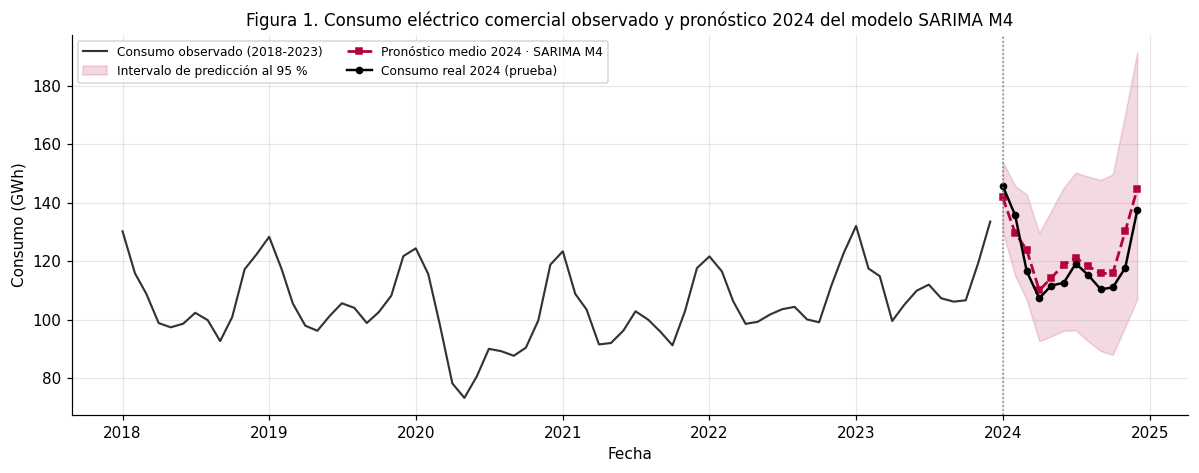

In [5]:
tabla_2023, pred23, inf23, sup23 = evaluar("2022-12", "2023-01", "2023-12")
tabla_2024, pred24, inf24, sup24 = evaluar("2023-12", "2024-01", "2024-12")
resumen = pd.concat({"Validación 2023": tabla_2023, "Prueba 2024": tabla_2024})

apertura = {
    "2024 no participa en el ajuste": modelo_final.nobs == 108 and modelo_final.fittedvalues.index.max() < pd.Timestamp("2024-01-01") and SELLO_2024,
    "modelo congelado antes de evaluar 2024":
        np.allclose(pred24, np.exp(CONGELADO["m"] + CONGELADO["sd"] ** 2 / 2)) and np.allclose(sup24, np.exp(CONGELADO["m"] + Z95 * CONGELADO["sd"]))
        and np.allclose(inf24, np.exp(CONGELADO["m"] - Z95 * CONGELADO["sd"])) and huella(modelo_final.params, m24, sd24) == HUELLA_CONGELADO,
}
assert all(apertura.values())

real24 = test_final.to_numpy()
naive24, naive23 = y.shift(12)["2024-01":"2024-12"].to_numpy(), y.shift(12)["2023-01":"2023-12"].to_numpy()
assert np.array_equal(naive24, y["2023-01":"2023-12"].to_numpy()) and np.array_equal(naive23, y["2022-01":"2022-12"].to_numpy())
f24, n24, d24 = (tabla_2024.loc[k] for k in ("Modelo final", "Naive estacional", "Naive con deriva"))
f23, n23 = tabla_2023.loc["Modelo final"], tabla_2023.loc["Naive estacional"]
assert round(n23["RMSE"], 2) == S3["rmse_naive"] and round(n23["MAE"], 2) == S3["mae_naive"]
assert np.allclose(pred23, media_s3, atol=1e-6), "2023 y 2024 deben usar la misma retransformación (media)"
escala = lambda fin: float((y[:fin] - y[:fin].shift(12)).dropna().abs().mean())       # misma escala que `evaluar`
esc23, esc24 = escala("2022-12"), escala("2023-12")
dentro = (real24 >= inf24) & (real24 <= sup24)
cob24, dentro24 = cobertura_y_ancho(real24, inf24, sup24), int(dentro.sum())
consumo_medio_24 = real24.mean()
red_rmse24, red_mae24 = 100 * (1 - f24["RMSE"] / n24["RMSE"]), 100 * (1 - f24["MAE"] / n24["MAE"])
cob = lambda r, lo, hi: f"{int(((r >= lo) & (r <= hi)).sum())}/12"

maestra = pd.concat({"Validación 2023": tabla_2023, "Prueba 2024": tabla_2024}).rename(index={"Modelo final": MODELO}, level=1)
maestra["Cobertura IC 95 %"] = [cob(real_2023, inf23, sup23), "—", "—", cob(real24, inf24, sup24), "—", "—"]
display(maestra.style.format({"RMSE": "{:.2f}", "MAE": "{:.2f}", "MASE": "{:.3f}", "ME": "{:+.2f}"}, decimal=",")
        .set_caption("Tabla 3. SARIMA M4 (media retransformada) y referencias naive en validación 2023 y prueba 2024 (GWh; ME > 0: subestima)"))
guardar_tabla(maestra, "tabla3_evaluacion_2023_2024.csv")
print(f"[OK] 2024 no participa en el ajuste | [OK] modelo congelado antes de evaluar 2024")
print(f"2024: RMSE −{red_rmse24:.1f} % y MAE −{red_mae24:.1f} % frente al naive | MAE = {100 * f24['MAE'] / consumo_medio_24:.1f} % del consumo "
      f"mensual medio | IC 95 %: {dentro24}/12, ancho medio {cob24['Ancho medio']:.2f} GWh")

fig, ax = plt.subplots(figsize=(11, 4.4))
obs = y["2018-01":"2023-12"]
ax.plot(obs.index, obs, color="#333333", lw=1.4, label="Consumo observado (2018-2023)")
ax.fill_between(test_final.index, inf24, sup24, color=ROJO, alpha=0.15, label="Intervalo de predicción al 95 %")
ax.plot(test_final.index, pred24, color=ROJO, lw=1.8, ls="--", marker="s", ms=3.5, label=f"Pronóstico medio 2024 · {MODELO}")
ax.plot(test_final.index, real24, color="k", lw=1.6, marker="o", ms=4, label="Consumo real 2024 (prueba)")
ax.axvline(pd.Timestamp("2024-01-01"), color="#777777", ls=":", lw=1)
ax.set(xlabel="Fecha", ylabel="Consumo (GWh)", title="Figura 1. Consumo eléctrico comercial observado y pronóstico 2024 del modelo SARIMA M4")
ax.legend(loc="upper left", ncol=2)
plt.tight_layout(); guardar(fig, "figura1_pronostico_2024.png"); plt.show()

Reestimado con 2015–2023, M4 obtiene **MASE = 0,82** en 2024 y supera al naive estacional (MASE = 1,02), con 26,6 % menos RMSE y 20,1 % menos MAE; su error absoluto medio equivale al 4,4 % del consumo mensual. El MASE se interpreta respecto de la escala histórica del naive estacional usada en su denominador; la comparación directa del desempeño en 2024 se complementa con RMSE y MAE calculados sobre el mismo conjunto de prueba. Los 12 meses caen en el IC 95 % (ancho medio 50,7 GWh): la cobertura 12/12 es favorable, pero con solo 12 meses cada observación representa 8,33 puntos porcentuales de cobertura; por ello, un único año de evaluación no permite demostrar una calibración perfecta de los intervalos.

El naive con deriva obtiene menor RMSE (5,80 GWh) y menor MAE en 2024; no se sustituye M4 porque 2024 constituye el conjunto final de prueba y utilizarlo para seleccionar nuevamente el modelo produciría sesgo de selección.

## 4. Seguimiento del sesgo

Retroalimentación de la S3: vigilar la subestimación de 2023 al reestimar con datos hasta 2023. El código compara 2023 con 2024 y determina si el sesgo persiste, disminuye o cambia de signo.

In [6]:
def sesgo(real, pred):
    e = np.asarray(real, float) - np.asarray(pred, float)
    return {"ME (GWh)": e.mean(), "Meses subestimados": int((e > 0).sum()), "Meses sobrestimados": int((e < 0).sum()),
            "Consumo anual real (GWh)": float(np.sum(real)), "Consumo anual pronosticado (GWh)": float(np.sum(pred)),
            "Diferencia anual (%)": 100 * (np.sum(pred) / np.sum(real) - 1)}

s23, s24 = sesgo(real_2023, pred23), sesgo(real24, pred24)          # ambos con la media retransformada
assert round(s23["ME (GWh)"], 2) == S3["me"] and s23["Meses subestimados"] == S3["subestimados"]
tabla_sesgo = pd.DataFrame({"Validación 2023": s23, "Prueba 2024": s24})
display(tabla_sesgo.style.format("{:+.2f}", subset=pd.IndexSlice[["ME (GWh)"], :], decimal=",")
        .format("{:.0f}", subset=pd.IndexSlice[["Meses subestimados", "Meses sobrestimados"], :])
        .format("{:.1f}", subset=pd.IndexSlice[["Consumo anual real (GWh)", "Consumo anual pronosticado (GWh)", "Diferencia anual (%)"], :], decimal=",")
        .set_caption("Tabla 4. Sesgo de M4 en 2023 y 2024 (ME > 0 = subestimación)"))
guardar_tabla(tabla_sesgo, "tabla4_sesgo.csv")

me23, me24 = s23["ME (GWh)"], s24["ME (GWh)"]
veredicto = "cambia de signo" if np.sign(me24) != np.sign(me23) else ("disminuye" if abs(me24) < abs(me23) else "persiste")
total = y.groupby(y.index.year).sum()
g23, g24, g24_pron = (100 * (total[2023] / total[2022] - 1), 100 * (total[2024] / total[2023] - 1), 100 * (pred24.sum() / total[2023] - 1))
print(f"Veredicto: la subestimación {veredicto.upper()} (ME {me23:+.2f} → {me24:+.2f} GWh) | crecimiento observado 2023 = {g23:+.1f} %, "
      f"2024 = {g24:+.1f} % | crecimiento 2024 proyectado por M4 = {g24_pron:+.1f} %")

,Validación 2023,Prueba 2024
ME (GWh),"+3,21","-3,66"
Meses subestimados,9,2
Meses sobrestimados,3,10
Consumo anual real (GWh),"1363,9","1440,6"
Consumo anual pronosticado (GWh),"1325,4","1484,5"
Diferencia anual (%),"-2,8","3,0"


Veredicto: la subestimación CAMBIA DE SIGNO (ME +3.21 → -3.66 GWh) | crecimiento observado 2023 = +6.1 %, 2024 = +5.6 % | crecimiento 2024 proyectado por M4 = +8.8 %


**La subestimación cambia de signo**: de 9 de 12 meses subestimados en 2023 (ME = +3,21 GWh; −2,8 % anual) a 10 de 12 sobrestimados en 2024 (ME = −3,66 GWh; +3,0 % anual). M4 incorporó el alza de 6,1 % de 2023 y proyectó +8,8 % para 2024, frente a +5,6 % observado. No se corrige el modelo con el error de 2024 (sería usar la prueba para ajustar); la sensibilidad del nivel se declara como limitación.

## 5. Sustento técnico acumulado S2–S4

Tabla 5. Cadena de evidencia (S2 y S3: cifras de sus notebooks, reproducidas en esta ejecución; S4: esta ejecución). El detalle de las siete alternativas de la Semana 2 está en la Tabla 5b.

| Etapa | Evidencia | Decisión |
|---|---|---|
| S2 · Transformación y órdenes | Box-Cox λ̂ = 0,004; con ∇∇₁₂, ADF p < 0,001 y KPSS p ≥ 0,10; d = 2 sobrediferencia (ρ1 = −0,425) (Dickey y Fuller, 1979; Kwiatkowski et al., 1992) | log, d = 1, D = 1, s = 12 |
| S2 · Selección | RMSE / MAE 2023 (GWh): **M4 (0,1,0)(1,1,0)₁₂ 4,12 / 3,71**; M1 (0,1,0)(0,1,1)₁₂ 7,20 / 6,71 (menor AIC de M1–M4, −300,0); M2 (0,1,1)(0,1,1)₁₂ 7,07 / 6,56; M3 (1,1,0)(0,1,1)₁₂ 7,09 / 6,58; M6 = M2 + covid + agudo 5,71 / 5,20 (menor AIC global, −331,4); naive estacional 7,26 / 6,53; naive con deriva 4,72 / 4,22 | M4 seleccionado por menor error fuera de muestra (Box et al., 2016); detalle en Tabla 5b |
| S2 · Residuos | Ljung-Box p = 0,679 (K = 12) y 0,059 (K = 24); Jarque-Bera p = 0,564 (Ljung y Box, 1978) | M4 utilizable con reservas |
| S3 · Memoria larga | H = 0,584, compatible con ruido blanco (n = 83); ARFIMA: RMSE 2023 = 4,19 frente a 4,12 GWh de M4 (Granger y Joyeux, 1980) | Descartar ARFIMA |
| S3 · Volatilidad | ARCH-LM p = 0,786; Ljung-Box de residuos² p = 0,829; GARCH no cambia la cobertura (Bollerslev, 1986) | Descartar GARCH: sin mejora sustantiva |
| S4 · Prueba 2024 | Media retransformada: MASE = 0,82 (naive estacional 1,02); ME = −3,66 GWh; cobertura 12/12 | Mantener M4 |
| S4 · Regla de contratación | Q50 → Q75: déficit −91,7 %, excedente +98,34 GWh (Tabla 6) | Contratar τ* = c_u / (c_u + c_o) |

In [7]:
# Tabla 5b. Alternativas de la Semana 2 recalculadas con los mismos datos y criterios de la S2: estimación 2015-2022,
# 12 pronósticos desde 2022-12 (validación 2023) y la MISMA retransformación (media_lognormal) para todos los modelos en log.
X_s2 = pd.DataFrame({"covid": df["covid"].astype(float),
                     "agudo": ((df.index >= "2020-04-01") & (df.index <= "2020-06-01")).astype(float)}, index=df.index)
assert (X_s2.loc["2023-01":"2023-12"] == 0).all().all()

def estimar_s2(orden, orden_est, cols):
    """Estimación de la S2 (L-BFGS, maxiter = 200; Powell si no converge) y pronóstico 2023 con media_lognormal."""
    mod = SARIMAX(log_y[:"2022-12"], exog=None if cols is None else X_s2.loc[:"2022-12", cols], order=orden, seasonal_order=orden_est)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        fit = mod.fit(disp=False, maxiter=200)
    if any(issubclass(a.category, ConvergenceWarning) for a in avisos) or not fit.mle_retvals.get("converged", True):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = mod.fit(start_params=fit.params, method="powell", maxiter=1000, disp=False)
    assert fit.nobs == 96 and fit.fittedvalues.index.max() == pd.Timestamp("2022-12-01"), "el ajuste no debe ver 2023 ni 2024"
    return fit, media_lognormal(fit.get_forecast(12, exog=None if cols is None else X_s2.loc["2023-01":"2023-12", cols]))

CANDIDATOS_S2 = {"M1": ((0, 1, 0), (0, 1, 1, 12), None), "M2": ((0, 1, 1), (0, 1, 1, 12), None), "M3": ((1, 1, 0), (0, 1, 1, 12), None),
                 "M4": ((0, 1, 0), (1, 1, 0, 12), None), "M6": ((0, 1, 1), (0, 1, 1, 12), ["covid", "agudo"])}
ajustes_s2, pred_s2 = {}, {}
for k, (o, oe, cols) in CANDIDATOS_S2.items():
    ajustes_s2[k], pred_s2[k] = estimar_s2(o, oe, cols)
v22 = y[:"2022-12"].to_numpy()
pred_s2["Naive estacional"] = y["2022"].to_numpy()
pred_s2["Naive con deriva"] = y["2022"].to_numpy() * (1 + np.mean(v22[12:] / v22[:-12] - 1))
met_s2 = {k: metricas(real_2023, p) for k, p in pred_s2.items()}
seleccion_s2 = min(CANDIDATOS_S2, key=lambda k: met_s2[k]["RMSE"])          # regla de la S2: menor RMSE, MAE como respaldo
assert seleccion_s2 == "M4" == min(CANDIDATOS_S2, key=lambda k: met_s2[k]["MAE"])

DECISION_S2 = {"M1": "Descartado: menor AIC de M1–M4, pero error cercano al naive estacional",
               "M2": "Descartado: término regular no significativo; error cercano al naive estacional",
               "M3": "Descartado: término regular no significativo; error cercano al naive estacional",
               "M4": "Seleccionado: menor RMSE y MAE de validación",
               "M6": "Complementario (intervención): menor AIC global, peor pronóstico que M4 y que la deriva",
               "Naive estacional": "Referencia obligatoria",
               "Naive con deriva": "Referencia: solo M4 la supera"}
tabla_s2 = pd.DataFrame({
    "Especificación": {"M1": "SARIMA(0,1,0)(0,1,1)₁₂", "M2": "SARIMA(0,1,1)(0,1,1)₁₂", "M3": "SARIMA(1,1,0)(0,1,1)₁₂",
                       "M4": "SARIMA(0,1,0)(1,1,0)₁₂", "M6": "SARIMA(0,1,1)(0,1,1)₁₂ + covid + agudo",
                       "Naive estacional": "mismo mes de 2022", "Naive con deriva": "naive × (1 + crecimiento interanual medio)"},
    "Validación": {k: "2023 (entrenamiento 2015–2022)" for k in pred_s2},
    "Retransformación": {k: "exp(μ + σ²/2)" if k in CANDIDATOS_S2 else "— (escala original)" for k in pred_s2},
    "AIC": {k: ajustes_s2[k].aic if k in ajustes_s2 else np.nan for k in pred_s2},
    "RMSE 2023": {k: met_s2[k]["RMSE"] for k in pred_s2}, "MAE 2023": {k: met_s2[k]["MAE"] for k in pred_s2},
    "Decisión": DECISION_S2})
tabla_s2.index.name = "Modelo"
display(tabla_s2.style.format({"AIC": "{:.1f}", "RMSE 2023": "{:.2f}", "MAE 2023": "{:.2f}"}, decimal=",", na_rep="—")
        .apply(lambda f: ["font-weight: bold" if f.name == seleccion_s2 else "" for _ in f], axis=1)
        .set_caption("Tabla 5b. Alternativas de la Semana 2 en la validación 2023 (GWh), con retransformación homogénea"))
guardar_tabla(tabla_s2, "tabla5b_alternativas_s2_validacion_2023.csv")
print(f"Seleccionado con la validación de la S2: {seleccion_s2} | 2024 no participa en esta comparación ni reabre la selección")

,Especificación,Validación,Retransformación,AIC,RMSE 2023,MAE 2023,Decisión
Modelo,,,,,,,
M1,"SARIMA(0,1,0)(0,1,1)₁₂",2023 (entrenamiento 2015–2022),exp(μ + σ²/2),"-300,0","7,20","6,71","Descartado: menor AIC de M1–M4, pero error cercano al naive estacional"
M2,"SARIMA(0,1,1)(0,1,1)₁₂",2023 (entrenamiento 2015–2022),exp(μ + σ²/2),"-298,2","7,07","6,56",Descartado: término regular no significativo; error cercano al naive estacional
M3,"SARIMA(1,1,0)(0,1,1)₁₂",2023 (entrenamiento 2015–2022),exp(μ + σ²/2),"-298,2","7,09","6,58",Descartado: término regular no significativo; error cercano al naive estacional
M4,"SARIMA(0,1,0)(1,1,0)₁₂",2023 (entrenamiento 2015–2022),exp(μ + σ²/2),"-277,8","4,12","3,71",Seleccionado: menor RMSE y MAE de validación
M6,"SARIMA(0,1,1)(0,1,1)₁₂ + covid + agudo",2023 (entrenamiento 2015–2022),exp(μ + σ²/2),"-331,4","5,71","5,20","Complementario (intervención): menor AIC global, peor pronóstico que M4 y que la deriva"
Naive estacional,mismo mes de 2022,2023 (entrenamiento 2015–2022),— (escala original),—,"7,26","6,53",Referencia obligatoria
Naive con deriva,naive × (1 + crecimiento interanual medio),2023 (entrenamiento 2015–2022),— (escala original),—,"4,72","4,22",Referencia: solo M4 la supera


Seleccionado con la validación de la S2: M4 | 2024 no participa en esta comparación ni reabre la selección


## 6. Selección final y recomendación

**Modelo seleccionado.** M4 = SARIMA(0,1,0)(1,1,0)₁₂ sobre log(consumo) es el modelo seleccionado bajo el protocolo de validación definido en la Semana 2 —menor error fuera de muestra en 2023 y único candidato que superó también al naive con deriva— y se mantiene sin reselección posterior sobre el conjunto final de prueba. En 2024 supera al naive estacional, aunque el naive con deriva obtiene menor error puntual; tiene un solo coeficiente y no incorpora componentes cuyo aporte no se haya demostrado.

**Recomendación operativa.** Contratar mes a mes el cuantil τ* = c_u / (c_u + c_o) de la distribución predictiva, Q_τ = exp(μ + z_τ σ): como quedarse corto cuesta más que sobrar (c_u > c_o), τ* > 0,5 y el volumen queda sobre la mediana. τ* **no puede calcularse** porque los documentos del curso no entregan valores de c_u ni c_o; su efecto se cuantifica en 2024 comparando la mediana (Q50) con Q75 (Q80 figura solo como referencia en la Tabla 6). Además, reestimar cada diciembre y vigilar el sesgo.

,τ,Contratado (GWh),Déficit (GWh),Excedente (GWh),Meses con déficit,Meses con excedente,Costo relativo (c_u/c_o = 3)
Q50,"0,50","1475,6","10,38","45,41",2,10,"76,56"
Q75,"0,75","1583,5","0,86","143,76",1,11,"146,33"
Q80,"0,80","1611,5","0,00","170,96",0,12,"170,96"


,Contratado: cambio (GWh),Contratado: cambio (%),Déficit: reducción (%),Excedente: aumento (GWh),Excedente: aumento (%)
Q50 → Q75,"+107,9","+7,3","91,7","+98,4","+216,6"


Q50 → Q75: déficit 10.38 → 0.86 GWh (−91.7 %) | excedente 45.41 → 143.76 GWh | meses bajo la mediana: 10/12


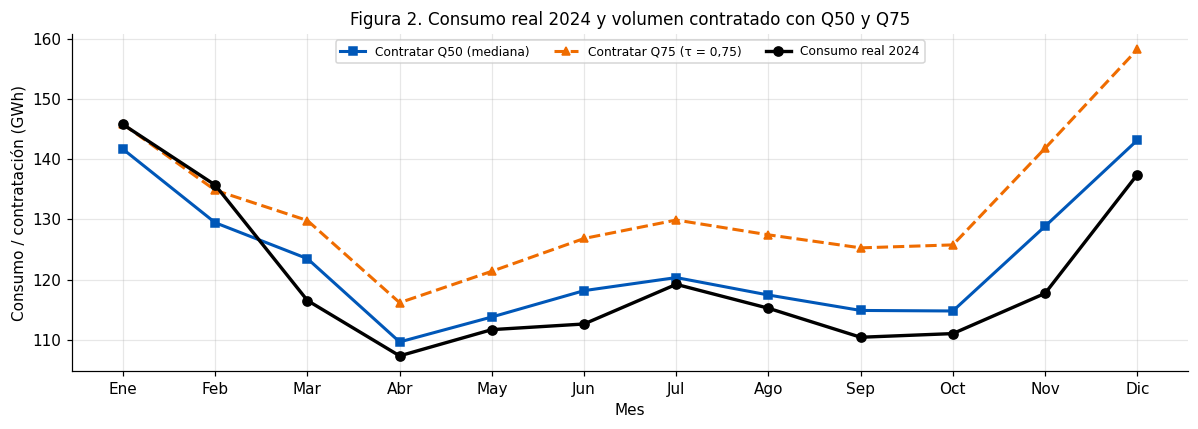

In [8]:
# Efecto de la regla en 2024: cuantiles del pronóstico congelado (sin corrección + s²/2) frente al consumo real
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
REGLAS = {"Q50": 0.50, "Q75": 0.75, "Q80": 0.80}
Q24 = {e: np.exp(CONGELADO["m"] + norm.ppf(t) * CONGELADO["sd"]).to_numpy() for e, t in REGLAS.items()}
assert np.allclose(Q24["Q50"], np.exp(CONGELADO["m"]))
R_COSTO = 3                                                     # c_u/c_o = 3 ⇔ τ* = 0,75 (escenario ilustrativo, c_o = 1)
filas = {}
for e, Q in Q24.items():
    deficit, excedente = np.maximum(real24 - Q, 0), np.maximum(Q - real24, 0)
    filas[e] = {"τ": REGLAS[e], "Contratado (GWh)": Q.sum(), "Déficit (GWh)": deficit.sum(), "Excedente (GWh)": excedente.sum(),
                "Meses con déficit": int((deficit > 0).sum()), "Meses con excedente": int((excedente > 0).sum()), f"Costo relativo (c_u/c_o = {R_COSTO})": (R_COSTO * deficit + excedente).sum()}
tabla_regla = pd.DataFrame(filas).T
guardar_tabla(tabla_regla, "tabla6_contratacion_q50_q75_q80.csv")
reduccion_deficit = 100 * (1 - tabla_regla.loc["Q75", "Déficit (GWh)"] / tabla_regla.loc["Q50", "Déficit (GWh)"])
display(tabla_regla.style.format({"τ": "{:.2f}", "Contratado (GWh)": "{:.1f}", "Déficit (GWh)": "{:.2f}", "Excedente (GWh)": "{:.2f}",
                                  "Meses con déficit": "{:.0f}", "Meses con excedente": "{:.0f}", f"Costo relativo (c_u/c_o = {R_COSTO})": "{:.2f}"}, decimal=",")
        .set_caption(f"Tabla 6. Efecto de la regla de contratación en 2024 (consumo real = {real24.sum():.1f} GWh; costo en GWh equivalentes)".replace(f"{real24.sum():.1f}", f"{real24.sum():.1f}".replace(".", ","))))
q50, q75 = tabla_regla.loc["Q50"], tabla_regla.loc["Q75"]
cambio_q75 = {"Contratado: cambio (GWh)": q75["Contratado (GWh)"] - q50["Contratado (GWh)"],
              "Contratado: cambio (%)": 100 * (q75["Contratado (GWh)"] / q50["Contratado (GWh)"] - 1),
              "Déficit: reducción (%)": reduccion_deficit,
              "Excedente: aumento (GWh)": q75["Excedente (GWh)"] - q50["Excedente (GWh)"],
              "Excedente: aumento (%)": 100 * (q75["Excedente (GWh)"] / q50["Excedente (GWh)"] - 1)}
display(pd.DataFrame(cambio_q75, index=["Q50 → Q75"]).style.format("{:+.1f}", decimal=",")
        .format("{:.1f}", subset=["Déficit: reducción (%)"], decimal=",").set_caption("Tabla 6b. Cambio al pasar de Q50 a Q75 en 2024"))
guardar_tabla(pd.DataFrame(cambio_q75, index=["Q50 → Q75"]), "tabla6b_cambio_q50_q75.csv")
print(f"Q50 → Q75: déficit {tabla_regla.loc['Q50', 'Déficit (GWh)']:.2f} → {tabla_regla.loc['Q75', 'Déficit (GWh)']:.2f} GWh (−{reduccion_deficit:.1f} %) | "
      f"excedente {tabla_regla.loc['Q50', 'Excedente (GWh)']:.2f} → {tabla_regla.loc['Q75', 'Excedente (GWh)']:.2f} GWh | "
      f"meses bajo la mediana: {int((real24 <= Q24['Q50']).sum())}/12")

fig, ax = plt.subplots(figsize=(11, 4.0))
x = np.arange(12)
ax.plot(x, Q24["Q50"], color=AZUL, lw=2, marker="s", ms=5, label="Contratar Q50 (mediana)")
ax.plot(x, Q24["Q75"], color=NARANJA, lw=2, ls="--", marker="^", ms=5, label="Contratar Q75 (τ = 0,75)")
ax.plot(x, real24, color="k", lw=2.2, marker="o", ms=6, label="Consumo real 2024")
ax.set_xticks(x, MESES)
ax.set(xlabel="Mes", ylabel="Consumo / contratación (GWh)", title="Figura 2. Consumo real 2024 y volumen contratado con Q50 y Q75")
ax.legend(loc="upper center", ncol=3)
plt.tight_layout(); guardar(fig, "figura2_q50_q75_2024.png"); plt.show()

Al pasar de Q50 a Q75, el déficit anual disminuye de 10,38 a 0,86 GWh, una reducción de 91,7 %, mientras el excedente aumenta en 98,34 GWh (+216,6 %, de 45,41 a 143,75 GWh) y el volumen contratado crece 107,9 GWh (+7,3 %). Subir el cuantil reduce fuertemente la exposición a déficit, pero incrementa la sobrecontratación. Q75 no es universalmente óptimo: τ* depende de c_u/c_o, que no están disponibles. Con c_u/c_o = 3 (τ* = 0,75), el costo relativo realizado fue mayor con Q75 que con Q50 (146,32 frente a 76,56) porque M4 sobrestimó 2024 (consumo bajo la mediana en 10 de 12 meses): el beneficio de τ* es esperado, no garantizado en un año con sesgo, y τ no se elige mirando 2024.

## 7. Limitaciones

- **Prueba de 12 meses:** el MASE, la cobertura y el efecto de la regla provienen de un solo año y un solo origen de pronóstico.
- **COVID-19 en el ajuste:** 22 meses con `covid` = 1; el mayor residuo sigue siendo 2020-04 (3,4 s), lo que puede ensanchar los intervalos.
- **Rezago 24:** ρ24 = −0,31 sigue fuera de ±0,201; es compatible con dependencia estacional remanente que M4 no captura del todo.
- **Cambio de signo del sesgo:** −2,8 % en 2023 y +3,0 % en 2024; el nivel del pronóstico depende del último año incorporado.
- **Costos no observados:** sin valores de c_u y c_o, τ* no es calculable y el costo de la Tabla 6 es solo un escenario relativo.

## 8. Conclusiones

1. **M4 fue seleccionado en la S2 frente a las alternativas originales:** menor RMSE / MAE de validación 2023 (4,12 / 3,71 GWh) que M1, M2, M3, M6 y ambos naive.
2. **ARFIMA y GARCH no mejoraron el modelo en la S3:** RMSE 4,19 frente a 4,12 GWh con ARFIMA, y sin efectos ARCH (p = 0,786) ni cambio sustantivo en los intervalos con GARCH.
3. **Con retransformación unificada, M4 se mantiene competitivo en 2024:** MASE = 0,82 frente a 1,02 del naive estacional (RMSE 6,01 frente a 8,19 GWh), con cobertura 12/12 del IC 95 %.
4. **El sesgo cambia de signo:** de 9/12 meses subestimados en 2023 (ME = +3,21 GWh) a 10/12 sobrestimados en 2024 (ME = −3,66 GWh).
5. **Regla de contratación:** subir de Q50 a Q75 reduce el déficit de 2024 en 91,7 %, pero aumenta el excedente de 45,41 a 143,75 GWh; el cuantil definitivo depende de c_u/c_o, que DEL debe cuantificar.

### Anexo opcional: extensión operativa 2025

Cerrada la evaluación, M4 se reestima con 2015–2024 sin cambiar su especificación para pronosticar 2025, que no tiene datos reales para evaluarse; el pronóstico puntual es la media retransformada. La tabla muestra el volumen que implicaría cada cuantil τ (suma de cuantiles mensuales); no recomienda un τ, que depende solo de los costos.

In [9]:
assert {"tabla_2024", "maestra", "tabla_sesgo"} <= set(globals()), "la evaluación 2024 debe cerrarse antes"
modelo_op = ajustar_sarima(log_y)
assert modelo_op.mle_retvals.get("converged", True) and modelo_op.nobs == 120 and tuple(modelo_op.model.order) == ORDEN
p25 = modelo_op.get_forecast(12)
m25 = p25.predicted_mean
sd25 = np.sqrt(p25.var_pred_mean)
total25_med, total25_media = float(np.exp(m25).sum()), float(media_lognormal(p25).sum())

COSTO_DEFICIT = None      # c_u: costo por GWh contratado de menos. No disponible: no se inventa
COSTO_EXCEDENTE = None    # c_o: costo por GWh contratado de más. No disponible: no se inventa
TAU = COSTO_DEFICIT / (COSTO_DEFICIT + COSTO_EXCEDENTE) if COSTO_DEFICIT is not None and COSTO_EXCEDENTE is not None else None

TAUS = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
tabla_tau = pd.DataFrame({"Volumen 2025 (GWh)": [float(np.exp(m25 + norm.ppf(t) * sd25).sum()) for t in TAUS]}, index=pd.Index(TAUS, name="τ"))
tabla_tau["Sobre la mediana (%)"] = 100 * (tabla_tau["Volumen 2025 (GWh)"] / total25_med - 1)
volumen_tau = tabla_tau["Volumen 2025 (GWh)"]
display(tabla_tau.T.style.format("{:.1f}", decimal=",").format_index("{:.2f}", axis=1, decimal=",")
        .set_caption("Tabla 7. Volumen 2025 según el cuantil τ de la distribución predictiva de M4 (reestimado con 2015-2024)"))
print(f"2025: pronóstico medio = {total25_media:.1f} GWh (mediana {total25_med:.1f}) | variación del medio frente a 2024 = {100 * (total25_media / total[2024] - 1):+.1f} % | "
      + (f"τ* = {TAU:.3f} → {np.exp(m25 + norm.ppf(TAU) * sd25).sum():.1f} GWh" if TAU is not None
         else "τ* no calculable: faltan c_u y c_o (solo se sabe que τ* > 0,5)"))

τ,"0,50","0,60","0,70","0,80","0,90","0,95"
Volumen 2025 (GWh),"1500,3","1540,2","1584,2","1637,5","1714,6","1781,4"
Sobre la mediana (%),"0,0","2,7","5,6","9,1","14,3","18,7"


2025: pronóstico medio = 1509.2 GWh (mediana 1500.3) | variación del medio frente a 2024 = +4.8 % | τ* no calculable: faltan c_u y c_o (solo se sabe que τ* > 0,5)


## Control de reproducibilidad

In [10]:
# Cifras citadas en el texto frente a esta ejecución. Las que dependen del optimizador de máxima verosimilitud admiten
# ±1 en el último dígito (como en el control de la S2), porque su punto de detención varía levemente entre plataformas.
from statsmodels.tools.sm_exceptions import ConvergenceWarning
CITADAS = {
    "Φ1 S4": (phi_s4, -0.36, 2), "ee Φ1": (se_phi, 0.094, 3), "ΔΦ1 en ee": (abs(phi_s4 - S3["phi"]) / se_phi, 0.5, 1),
    "AIC S4": (modelo_final.aic, -322.9, 1), "ρ24": (acf_final[24], -0.31, 2), "banda ACF": (banda_final, 0.201, 3),
    "Ljung-Box K = 24": (lb_final.lb_pvalue.iloc[1], 0.185, 3), "mayor residuo (s)": (z_final.max(), 3.4, 1),
    "meses covid en el ajuste": (int(df.loc[:"2023-12", "covid"].sum()), 22, 0),
    "RMSE 2024": (f24["RMSE"], 6.01, 2), "MAE 2024": (f24["MAE"], 5.33, 2), "MASE 2024": (f24["MASE"], 0.82, 2), "ME 2024": (f24["ME"], -3.66, 2),
    "RMSE naive 2024": (n24["RMSE"], 8.19, 2), "MASE naive 2024": (n24["MASE"], 1.02, 2), "RMSE deriva 2024": (d24["RMSE"], 5.80, 2),
    "reducción RMSE (%)": (red_rmse24, 26.6, 1), "reducción MAE (%)": (red_mae24, 20.1, 1),
    "MAE / consumo medio (%)": (100 * f24["MAE"] / consumo_medio_24, 4.4, 1),
    "cobertura 2024": (dentro24, 12, 0), "ancho medio 2024": (cob24["Ancho medio"], 50.7, 1),
    "ME 2023": (me23, 3.21, 2), "subestimados 2023": (s23["Meses subestimados"], 9, 0), "diferencia anual 2023 (%)": (s23["Diferencia anual (%)"], -2.8, 1),
    "sobrestimados 2024": (s24["Meses sobrestimados"], 10, 0), "diferencia anual 2024 (%)": (s24["Diferencia anual (%)"], 3.0, 1),
    "crecimiento 2023": (g23, 6.1, 1), "crecimiento 2024": (g24, 5.6, 1), "crecimiento 2024 en M4": (g24_pron, 8.8, 1),
    "déficit Q50": (tabla_regla.loc["Q50", "Déficit (GWh)"], 10.38, 2), "déficit Q75": (tabla_regla.loc["Q75", "Déficit (GWh)"], 0.86, 2),
    "reducción déficit (%)": (reduccion_deficit, 91.7, 1),
    "excedente Q50": (tabla_regla.loc["Q50", "Excedente (GWh)"], 45.41, 2), "excedente Q75": (tabla_regla.loc["Q75", "Excedente (GWh)"], 143.75, 2),
    "aumento excedente": (tabla_regla.loc["Q75", "Excedente (GWh)"] - tabla_regla.loc["Q50", "Excedente (GWh)"], 98.34, 2),
    "contratado Q50": (tabla_regla.loc["Q50", "Contratado (GWh)"], 1475.6, 1), "contratado Q75": (tabla_regla.loc["Q75", "Contratado (GWh)"], 1583.5, 1),
    "costo Q50 (r = 3)": (tabla_regla.loc["Q50", "Costo relativo (c_u/c_o = 3)"], 76.56, 2),
    "costo Q75 (r = 3)": (tabla_regla.loc["Q75", "Costo relativo (c_u/c_o = 3)"], 146.32, 2),
    "meses bajo la mediana 2024": (int((real24 <= Q24["Q50"]).sum()), 10, 0), "puntos de cobertura por mes": (100 / len(real24), 8.33, 2),
    "aumento excedente (%)": (cambio_q75["Excedente: aumento (%)"], 216.6, 1),
    "cambio contratado (GWh)": (cambio_q75["Contratado: cambio (GWh)"], 107.9, 1), "cambio contratado (%)": (cambio_q75["Contratado: cambio (%)"], 7.3, 1),
    "meses con excedente Q50": (tabla_regla.loc["Q50", "Meses con excedente"], 10, 0), "meses con excedente Q75": (tabla_regla.loc["Q75", "Meses con excedente"], 11, 0),
    "meses con déficit Q50": (tabla_regla.loc["Q50", "Meses con déficit"], 2, 0), "meses con déficit Q75": (tabla_regla.loc["Q75", "Meses con déficit"], 1, 0),
}

# Cifras publicadas en la Tabla 3 de la S2, frente a su recálculo en la Tabla 5b
TABLA5_S2 = {"M1": (7.20, 6.71), "M2": (7.07, 6.56), "M3": (7.09, 6.58), "M4": (4.12, 3.71), "M6": (5.71, 5.20),
             "Naive estacional": (7.26, 6.53), "Naive con deriva": (4.72, 4.22)}
for k, (r_, m_) in TABLA5_S2.items():
    CITADAS[f"RMSE {k} 2023"], CITADAS[f"MAE {k} 2023"] = (met_s2[k]["RMSE"], r_, 2), (met_s2[k]["MAE"], m_, 2)
CITADAS["AIC M1"], CITADAS["AIC M6"] = (ajustes_s2["M1"].aic, -300.0, 1), (ajustes_s2["M6"].aic, -331.4, 1)
# Cifras de la S3 (ARFIMA, ARCH-LM y residuos²), recalculadas sobre M4 estimado con 2015-2022
res_s3 = ajustes_s2["M4"].resid.iloc[13:]
hurst_s3 = calcular_exponente_hurst(res_s3)
p_s3_log = ajustes_s2["M4"].get_forecast(12)
arfima_23 = np.exp(p_s3_log.predicted_mean.to_numpy() + correccion_arfima(res_s3, hurst_s3 - 0.5, 12) + p_s3_log.var_pred_mean.to_numpy() / 2)
CITADAS.update({"H (S3)": (hurst_s3, 0.584, 3), "RMSE ARFIMA 2023": (metricas(real_2023, arfima_23)["RMSE"], 4.19, 2),
                "ARCH-LM (S3)": (het_arch(res_s3.to_numpy(), nlags=12)[1], 0.786, 3),
                "Ljung-Box residuos² (S3)": (acorr_ljungbox(res_s3.to_numpy() ** 2, lags=[12]).lb_pvalue.iloc[0], 0.829, 3)})
distintas = {k: (f"{float(v):.{dec}f}", f"{c:.{dec}f}") for k, (v, c, dec) in CITADAS.items()
             if abs(float(v) - c) > 1.5 * 10 ** -dec + 1e-12}

# Declaración de IA: última celda e idéntica a la de la Sumativa 3
IA_SHA256 = "61d6676261c85841bfd70b7fbb35263633db797c6aebc9f16d3b64da0935592c"
nombres = ("mcdi505_S4CAlarcon_FINAL.ipynb", "mcdi505_S4CAlarcon_SUMATIVA4_FINAL_MEJORADA.ipynb", "mcdi505_S4CAlarcon_SUMATIVA4.ipynb", "mcdi505_S4CAlarcon.ipynb", "mcdi505_S4calarcon.ipynb")
ruta_nb = next((Path(c) / n for c in (".", "notebooks/semana_4/S4") for n in nombres if (Path(c) / n).exists()), None)
ia_ok = None
if ruta_nb is not None:
    ultima = json.loads(ruta_nb.read_text(encoding="utf-8"))["cells"][-1]
    ia_ok = ultima["cell_type"] == "markdown" and hashlib.sha256("".join(ultima["source"]).encode("utf-8")).hexdigest() == IA_SHA256

comprobaciones = {
    "120 meses (2015-01 a 2024-12), frecuencia MS, sin duplicados ni faltantes":
        len(y) == 120 and y.index.freqstr == "MS" and not y.index.duplicated().any() and y.notna().all(),
    "modelo M4 = SARIMA(0,1,0)(1,1,0,12), sin exógenas, ARFIMA ni GARCH":
        tuple(modelo_final.model.order) == (0, 1, 0) and tuple(modelo_final.model.seasonal_order) == (1, 1, 0, 12)
        and modelo_final.model.k_exog == 0 and D_FRACCIONAL is None and not BANDAS_GARCH,
    "S2 reproducida: M4 con menor RMSE de validación 2023": seleccion_s2 == "M4",
    "train 2015-2023 (108) y test 2024 (12)": len(train_final) == 108 and len(test_final) == 12,
    "2024 no usado en el ajuste y modelo congelado antes de evaluarlo": all(apertura.values()),
    "una sola retransformación (media lognormal) en M1-M6 (2023) y en M4 (2023, 2024 y 2025)":
        all(np.allclose(pred_s2[k], media_lognormal(ajustes_s2[k].get_forecast(12, exog=None if c is None else X_s2.loc["2023-01":"2023-12", c])))
            for k, (_, _, c) in CANDIDATOS_S2.items())
        and np.allclose(pred_s2["M4"], pred23, atol=1e-3) and np.allclose(pred23, media_s3, atol=1e-6)
        and np.allclose(pred24, np.exp(m24 + sd24 ** 2 / 2)) and np.isclose(total25_media, np.exp(m25 + sd25 ** 2 / 2).sum()),
    "las 7 alternativas de la Semana 2 están en la Tabla 5b": list(tabla_s2.index) == list(TABLA5_S2),
    "naive correcto (mismo mes del año anterior)":
        np.array_equal(naive24, y["2023-01":"2023-12"].to_numpy()) and np.array_equal(naive23, y["2022-01":"2022-12"].to_numpy()),
    "RMSE, MAE, MASE y ME correctos (recalculados)":
        np.isclose(f24["RMSE"], np.sqrt(np.mean((real24 - pred24) ** 2))) and np.isclose(f24["MAE"], np.mean(np.abs(real24 - pred24)))
        and np.isclose(f24["MASE"], np.mean(np.abs(real24 - pred24)) / esc24) and np.isclose(f24["ME"], np.mean(real24 - pred24))
        and np.isclose(n24["MASE"], np.mean(np.abs(real24 - naive24)) / esc24),
    "cobertura correcta": np.isclose(f24["Cobertura IC 95 %"], dentro.mean()),
    "todos los ajustes SARIMA convergen (L-BFGS; Powell como respaldo)":
        all(a.mle_retvals.get("converged", False) for a in (ajuste_s3, modelo_final, modelo_op)),
    "tablas y figuras guardadas": all((CARPETA_TAB / n).exists() for n in ("tabla3_evaluacion_2023_2024.csv", "tabla4_sesgo.csv",
        "tabla6_contratacion_q50_q75_q80.csv", "tabla5b_alternativas_s2_validacion_2023.csv", "tabla6b_cambio_q50_q75.csv")) and (CARPETA_FIG / "figura1_pronostico_2024.png").exists(),
    "cuantiles de la regla sin corrección de media": np.allclose(Q24["Q75"], np.exp(m24 + norm.ppf(0.75) * sd24)),
    "cifras heredadas de la S3 reproducidas": all(continuidad.values()),
    f"cifras de texto = outputs ({len(CITADAS)})": not distintas,
    "notebook ejecuta sin errores (todas las secciones llegaron a este control)":
        all(v in globals() for v in ("df", "modelo_final", "maestra", "tabla_sesgo", "tabla_regla", "tabla_tau", "lb_final")),
}
if distintas:
    print("Cifras del texto que difieren de esta ejecución (calculada, citada):", distintas)
for nombre, ok in comprobaciones.items():
    print(f"[{'OK' if ok else 'FALLA'}] {nombre}")
print("[OK] declaración IA intacta" if ia_ok else "[FALLA] declaración IA modificada" if ia_ok is False
      else "[--] declaración IA: no verificable en este entorno")
print(f"Tablas y figuras guardadas en {CARPETA_FIG.as_posix()}")
assert all(comprobaciones.values()) and ia_ok is not False

[OK] 120 meses (2015-01 a 2024-12), frecuencia MS, sin duplicados ni faltantes
[OK] modelo M4 = SARIMA(0,1,0)(1,1,0,12), sin exógenas, ARFIMA ni GARCH
[OK] S2 reproducida: M4 con menor RMSE de validación 2023
[OK] train 2015-2023 (108) y test 2024 (12)
[OK] 2024 no usado en el ajuste y modelo congelado antes de evaluarlo
[OK] una sola retransformación (media lognormal) en M1-M6 (2023) y en M4 (2023, 2024 y 2025)
[OK] las 7 alternativas de la Semana 2 están en la Tabla 5b
[OK] naive correcto (mismo mes del año anterior)
[OK] RMSE, MAE, MASE y ME correctos (recalculados)
[OK] cobertura correcta
[OK] todos los ajustes SARIMA convergen (L-BFGS; Powell como respaldo)
[OK] tablas y figuras guardadas
[OK] cuantiles de la regla sin corrección de media
[OK] cifras heredadas de la S3 reproducidas
[OK] cifras de texto = outputs (68)
[OK] notebook ejecuta sin errores (todas las secciones llegaron a este control)
[OK] declaración IA intacta
Tablas y figuras guardadas en ../../../resultados/semana_4

## 9. Referencias

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, *31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., y Ljung, G. M. (2016). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Dickey, D. A., y Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, *74*(366a), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Granger, C. W. J., y Joyeux, R. (1980). An introduction to long-memory time series models and fractional differencing. *Journal of Time Series Analysis*, *1*(1), 15–29. https://doi.org/10.1111/j.1467-9892.1980.tb00297.x

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., y Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting*, *22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., y Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics*, *54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., y Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika*, *65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Seabold, S., y Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Universidad Andrés Bello. (s. f.-a). *MCDI505 — Análisis de series de tiempo. Caso transversal del curso: Documento base* [Notebook de Jupyter]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

Universidad Andrés Bello. (s. f.-b). *MCDI505 — Semana 4: Evaluación final en 2024 (anexo del informe)* [Plantilla de notebook de Jupyter `mcdi505_s4_plantilla.ipynb`]. Material docente del curso, Magíster en Ciencia de Datos e Inteligencia Artificial.

## Declaración de uso de Inteligencia Artificial

| Pregunta | Respuesta |
|---|---|
| ¿Utilizó herramientas de inteligencia artificial en esta entrega? | Sí. Se utilizaron herramientas de inteligencia artificial como apoyo durante el desarrollo y revisión de la entrega. |
| ¿Para qué se utilizaron? | Se utilizaron para apoyar la organización de ideas, revisar la coherencia del análisis, detectar posibles omisiones y mejorar la redacción académica del notebook. |
| ¿Cómo se verificaron sus aportes? | Los aportes fueron contrastados con los resultados obtenidos mediante la ejecución del notebook, las instrucciones y guía de la asignatura, la bibliografía utilizada y los controles de reproducibilidad implementados. |

Los resultados numéricos y las decisiones metodológicas se sustentan en la ejecución del código y en la evidencia obtenida durante el análisis.